# Advection 2D dans un labyrinthe par volumes finis
*Méthodes numériques en Génie Civil et Géologique, projet VF*

**Nom : Biémar Mattéo

In [3]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from tqdm import tqdm
import module1 as m1
import module2 as m2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Rappels du problème

Il est demandé de résoudre l’évolution temporelle du champ 2D d’un constituant purement advecté par ce fluide sur base de l’équation suivante : 

$$\frac{\partial c}{\partial t} + u\frac{\partial c}{\partial x} + v\frac{\partial c}{\partial y} = 0$$

Nous sommes en présence d'un fluide incompressible, ce qui permet d'écrire la continuité comme ceci :
$$\frac{\partial \rho}{\partial t} + \nabla \cdot (\rho \mathbf{v}) = 0$$
donc, 
$$\frac{\partial (uc)}{\partial x}+\frac{\partial (vc)}{\partial y}
= u\frac{\partial c}{\partial x}+v\frac{\partial c}{\partial y}
+ c\left(\frac{\partial u}{\partial x}+\frac{\partial v}{\partial y}\right)
= \mathbf u\cdot\nabla c + c\,\nabla\cdot\mathbf u 
= \mathbf u\cdot\nabla c + 0.$$

$$\frac{\partial c}{\partial t}+\mathbf u\cdot\nabla c=0
\;\Longleftrightarrow\;
\frac{\partial c}{\partial t}+\nabla\cdot(\mathbf u\,c)=0 .$$

Nous transformons donc cette équation de l'énoncé sous forme conservative, a l'aide du champ qui est à divergence nulle :


$$\frac{\partial c}{\partial t} + \frac{\partial (uc)}{\partial x} + \frac{\partial (vc)}{\partial y} = 0$$



Intégrée sur une cellule de volume $\Delta x\Delta y$ :

$$\frac{dc_{ij}}{dt} = \frac{Flux_{ouest}-Flux_{est}}{\Delta x} + \frac{Flux_{nord}-Flux_{sud}}{\Delta y}, \qquad Flux = u\,c_{face}$$

La forme conservative intégrée se prête parfaitement à la méthode des volumes finis sous cette forme de flux entrant et sortants.

## 2. Champ de vitesses

### 2.1 Potentiel
Le potentiel $\varphi$ (Laplace, différences finies) est fourni par `laplace.py`. Il est défini aux **centres** des cellules.

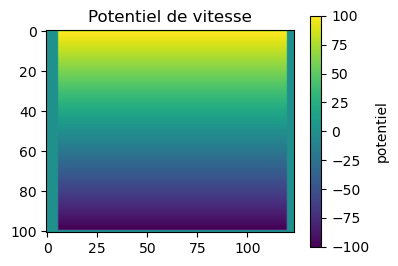

In [13]:
from laplace import compute
compute('labysimp.png', 'out')  #labysimp.png est le labyrinthe rectiligne
pot, domain = m1.charger_donnees()
ny, nx = pot.shape

plt.figure(figsize=(4,3)); plt.imshow(pot); plt.colorbar(label='potentiel'); plt.title('Potentiel de vitesse'); plt.show()

### 2.2 Vitesses aux faces
Les vitesses normales vivent sur les **faces** : $u$ de forme $(n_y, n_x+1)$, $v$ de forme $(n_y+1, n_x)$.

**Précision (Taylor, à développer).** Autour du milieu $x_f$ d'une face, avec $\varphi_{\pm}=\varphi(x_f\pm\Delta x/2)$ :

$$\varphi_\pm = \varphi \pm \frac{\Delta x}{2}\varphi' + \frac{\Delta x^2}{8}\varphi'' \pm \frac{\Delta x^3}{48}\varphi''' + \dots$$

$$\frac{\varphi_+-\varphi_-}{\Delta x} = \varphi' + \frac{\Delta x^2}{24}\varphi''' + \dots$$

Différence centrée sur grille décalée : **ordre 2**.

**Parois.** Une face a une vitesse non nulle seulement si les deux cellules voisines sont fluides ; sinon $u_n = 0$ (paroi imperméable).

**Convention de signe (À COMPLÉTER) :** expliquer le choix du signe de $u,v$ pour que le fluide aille de l'entrée (haut) vers la sortie (bas), et l'orientation de l'axe $y$ vers le bas.

In [ ]:
dx, dy = 1., 1.
u, v, u_c, v_c = m1.calculer_vitesses(pot, domain, dx, dy)
print("u", u.shape, "v", v.shape, "| v moyen (doit être > 0 si le fluide descend) :", v[v!=0].mean())

### 2.3 Norme de la vitesse (échelle logarithmique)

In [ ]:
norme = np.sqrt(u_c**2 + v_c**2)
plt.figure(figsize=(9,7))
plt.imshow(np.ma.masked_less_equal(norme, 1e-10), norm=LogNorm())
plt.colorbar(label='|vitesse| (log)'); plt.title('Norme de la vitesse au centre des cellules'); plt.show()

**Commentaire (À COMPLÉTER) :** zones rapides (passages étroits, conservation du débit), zones lentes, culs-de-sac à vitesse ~0. L'échelle log permet de voir plusieurs ordres de grandeur.

### 2.4 Vérification : divergence discrète
$$\mathrm{div}_{ij} = \frac{u_{i,j+1}-u_{i,j}}{\Delta x} + \frac{v_{i+1,j}-v_{i,j}}{\Delta y}$$
Attendue $\approx 0$ dans les cellules intérieures. Dans les cellules d'entrée/sortie (potentiel imposé), elle ne l'est pas : on y lit le débit.

In [ ]:
div = (u[:,1:]-u[:,:-1])/dx + (v[1:,:]-v[:-1,:])/dy
print("max |div| intérieur   :", np.abs(div[domain==1]).max())
print("max |div| entrée/sortie:", np.abs(div[domain==2]).max())
print("max |u|, |v|          :", np.abs(u).max(), np.abs(v).max())

**Discussion de la précision des vitesses (À COMPLÉTER) :** ordre 2, divergence résiduelle (précision du solveur), effet de la résolution dans les passages étroits.

## 3. Discrétisation spatiale

Seule la valeur $c_{face}$ change d'un schéma à l'autre ; le bilan de flux est identique.

### 3.1 Reconstruction constante (upwind, ordre 1)
$c$ est uniforme par cellule ; à la face on prend la cellule **amont** :
$c_{face}=c_{gauche}$ si $u>0$, $c_{droite}$ sinon.

### 3.2 Reconstruction linéaire limitée (Barth-Jespersen, ordre 2)
Dans chaque cellule : $c(\mathbf x)=c_{ij}+\phi_{ij}\,\mathbf s_{ij}\cdot(\mathbf x-\mathbf x_{ij})$ avec $\mathbf s$ la pente centrée.

Pour chaque face $f$ de la cellule, $\Delta_2=\mathbf s\cdot(\mathbf x_f-\mathbf x_{ij})$ est l'incrément voulu, et $\Delta_m$ l'incrément autorisé ($c_{max}-c_{ij}$ si $\Delta_2>0$, $c_{min}-c_{ij}$ sinon, sur la cellule et ses voisines fluides) :

$$\phi_f=\min\left(1,\frac{\Delta_m}{\Delta_2}\right),\qquad \phi_{ij}=\min_{f}\phi_f$$

**À COMPLÉTER :**
- Pourquoi le **minimum** sur les 4 faces ?
- Pourquoi $\phi=0$ redonne l'upwind ?
- Pourquoi la moyenne simple $\tfrac12(c_g+c_d)$ sans limiteur oscille-t-elle (nouveaux extrema) ?
- Limites de Barth-Jespersen (non dérivable, écrase les extrema lisses) ; alternative : Venkatakrishnan.

In [ ]:
import inspect
print(inspect.getsource(m2.calculer_dcdt))

## 4. Schémas temporels

Méthode des lignes : $\dfrac{dc}{dt}=f(c)$ avec $f=$ `calculer_dcdt`.

**Euler explicite** (ordre 1) : $c^{n+1}=c^n+\Delta t\,f(c^n)$

**RK2 (Heun)** (ordre 2, deux évaluations) :
$$k_1=f(c^n),\quad c^*=c^n+\Delta t\,k_1,\quad k_2=f(c^*),\quad c^{n+1}=c^n+\tfrac{\Delta t}{2}(k_1+k_2)$$

L'entrée ($c=c_{in}$) est réimposée sur $c^*$ **et** sur $c^{n+1}$.

**Ordre de RK2 (À COMPLÉTER) :** développer $f(c+\Delta t\,k_1)$ en Taylor et comparer à $c+\Delta t f+\frac{\Delta t^2}{2}f'f$.

## 5. Stabilité temporelle

### 5.1 Condition CFL (upwind + Euler, 1D, $u>0$)
$$c_j^{n+1}=(1-\sigma)c_j^n+\sigma c_{j-1}^n,\qquad \sigma=\frac{u\Delta t}{\Delta x}$$
Moyenne pondérée à coefficients positifs si $0\le\sigma\le1$ : **principe du maximum discret**.

### 5.2 Von Neumann
Avec $c_j^n=G^ne^{ij\theta}$ : $G=1-\sigma+\sigma e^{-i\theta}$ et
$$|G|^2=1-2\sigma(1-\sigma)(1-\cos\theta)\le 1\iff 0\le\sigma\le 1$$

### 5.3 En 2D
$$c_{ij}^{n+1}=(1-\sigma_x-\sigma_y)c_{ij}^n+\sigma_x c_{i,j-1}^n+\sigma_y c_{i-1,j}^n\;\Rightarrow\;\Delta t\left(\frac{|u|}{\Delta x}+\frac{|v|}{\Delta y}\right)\le1$$

On prend $\Delta t=\dfrac{CFL}{\max|u|/\Delta x+\max|v|/\Delta y}$ avec $CFL\le1$.

### 5.4 Schéma centré + Euler
$G=1-i\sigma\sin\theta$, $|G|^2=1+\sigma^2\sin^2\theta>1$ : instable pour tout $\Delta t$. **(À COMPLÉTER : développement de $|G|^2$)**. Avec RK2 : $|R|^2=1+\theta^4/4$, instabilité plus lente mais présente.

## 6. Simulation et validations

In [ ]:
def lancer(schema, temps='euler', CFL=0.5, nb_pas=1000, seuil=0.99, pas_stock=None, domain=domain):
    # état initial et entrée
    c = np.zeros_like(domain, dtype=np.float64)
    inlet = np.zeros_like(domain, dtype=bool); inlet[1,:] = (domain[1,:]==2)
    c_in = 1.0; c[inlet] = c_in
    # arrêt : cellule juste au-dessus de la sortie
    sortie = np.zeros_like(domain, dtype=bool); sortie[ny-2,:] = (domain[ny-2,:]==2)
    amont = np.zeros_like(domain, dtype=bool); amont[ny-3,:] = sortie[ny-2,:]
    dt = CFL/(np.abs(u).max()/dx + np.abs(v).max()/dy)
    pas = m2.euler if temps=='euler' else m2.rk2
    frames, tps = [c.copy()], [0.]
    for n in tqdm(range(nb_pas), desc=f'{schema}/{temps}'):
        c = pas(c, u, v, dx, dy, dt, inlet, c_in, schema, domain)
        if pas_stock and (n+1) % pas_stock == 0:
            frames.append(c.copy()); tps.append((n+1)*dt)
        if c[amont].max() >= seuil: break
    return c, dt, n+1, frames, tps

### 6.1 Couloir droit : solution exacte
Dans un couloir uniforme de vitesse $V$, $c(y,t)=1$ pour $y\le Vt$, $0$ au-delà.
On compare la position du front numérique ($c=0{,}5$) à $1+Vn\Delta t$ et la largeur du front ($0{,}9\to0{,}1$), qui doit croître en $\sqrt t$ pour l'upwind.

In [ ]:
# À COMPLÉTER : adapter j0 (colonne du couloir) et les instants
j0 = np.where(domain[ny//2]==1)[0][0]
V = np.abs(v[v!=0]).max()
c_fin, dt, n_fin, frames, tps = lancer('rc constante', 'euler', CFL=0.5, nb_pas=1000, pas_stock=10)
print("dt =", dt, "| arrêt au pas", n_fin)

for k, t in zip(range(len(frames)), tps):
    if k in (5, 10, 15):     # instants à ajuster selon n_fin
        profil = frames[k][:, j0]
        i_front = np.argmax(profil < 0.5)
        print(f"t={t:.1f}  front numérique ligne {i_front}  théorique {1+V*t:.1f}")
        plt.plot(profil, label=f't={t:.1f}')
plt.legend(); plt.xlabel('ligne i'); plt.ylabel('c'); plt.title('Profils le long du couloir'); plt.show()

### 6.2 Étude de la stabilité : influence du CFL (upwind + Euler)
Attendu : stable pour $CFL\le1$, divergence au-delà. **À COMPLÉTER** : tracer $\max c$ en fonction du pas pour CFL = 0,5 ; 1 ; 1,2.

In [ ]:
# Exemple de squelette : à adapter (mesurer c.max() sur domain==1 à chaque pas)
for CFL in (0.5, 1.0, 1.2):
    c, dt, n_fin, _, _ = lancer('rc constante', 'euler', CFL=CFL, nb_pas=150)
    print(f"CFL={CFL}: min={c[domain==1].min():.3e}  max={c[domain==1].max():.3e}")

### 6.3 Comparaison des schémas
Upwind / linéaire limité, Euler / RK2. **À COMPLÉTER** : tableau avec largeur du front, $c_{min}$, $c_{max}$, temps de calcul. Commenter : diffusion numérique (upwind) vs raideur du front (ordre 2 limité), coût de RK2 (×2).

In [ ]:
import time
resultats = {}
for schema in ('rc constante', 'rc linéaire'):
    for temps in ('euler', 'rk2'):
        t0 = time.time()
        c, dt, n_fin, _, _ = lancer(schema, temps, CFL=0.5, nb_pas=100)
        resultats[(schema, temps)] = c
        print(f"{schema:13s} {temps:5s}  min={c[domain==1].min():+.3e}  max={c[domain==1].max():.6f}  ({time.time()-t0:.1f}s)")

### 6.4 Étude de convergence (À COMPLÉTER)
Erreur sur la position/forme du front en fonction de $\Delta x$ (images de tailles croissantes), en log-log : pente $\approx1$ pour l'upwind, plus pour le linéaire limité.

## 7. Application au labyrinthe

In [ ]:
# Lancer sur le grand labyrinthe (long) : sauvegarder ensuite les résultats
c_lab, dt, n_fin, frames, tps = lancer('rc linéaire', 'rk2', CFL=0.5, nb_pas=10000, pas_stock=100)
print("pas effectués :", n_fin, " temps simulé :", n_fin*dt)

In [ ]:
# Images de c à plusieurs instants
idx = np.linspace(0, len(frames)-1, 6).astype(int)
fig, axs = plt.subplots(2, 3, figsize=(14,9))
for ax, k in zip(axs.ravel(), idx):
    ax.imshow(np.ma.masked_where(domain==0, frames[k]), vmin=0, vmax=1)
    ax.set_title(f't = {tps[k]:.1f}'); ax.axis('off')
plt.tight_layout(); plt.show()
# m1.creer_video(frames, tps, domain, nom='labyrinthe')   # si la fonction est dans module1

**Discussion critique (À COMPLÉTER) :**
- L'advection pure ne remplit pas les impasses (vitesse ~0 dedans).
- Diffusion numérique de l'upwind dans les coudes.
- Condition de sortie : accumulation de matière dans les cellules de sortie (faces sous la sortie nulles) ; arrêt de la simulation avant que le front n'y arrive.
- Coût : $\Delta t\propto \Delta x$ et nombre de cellules $\propto\Delta x^{-2}$.

## 8. Conclusion
**À COMPLÉTER :** ce qui a été validé (solution exacte, CFL, principe du maximum), les schémas comparés, les limites de l'étude et les pistes (vraie condition de sortie, Venkatakrishnan, RK3/RK4).